In [13]:
import numpy as np
import matplotlib.pyplot as plt


# Add files up one level to the path
import sys
sys.path.append("../..")

from regparam_selection import dp_cubic, dp_val

from scipy.misc import derivative

import jlinops

In [14]:
ground_truth = jlinops.piecewise_constant_1d_test_problem()[::15]
n = len(ground_truth)
np.random.seed(0)
noise_stdev = 0.01
noise_var = noise_stdev**2
A = jlinops.Gaussian1DBlurOperator(n, blur_sigma=3, mode="reflect")
A = jlinops.black_box_to_dense(A)
#A = jlinops.IdentityOperator((n,n))
b = (A @ ground_truth) + noise_stdev*np.random.normal(size=n)
grid = np.arange(n)

L, Wmat = jlinops.first_order_derivative_1d(n, boundary="none")
L = L.toarray()
Lopinv = (np.eye(Wmat.shape[0]) - Wmat @ np.linalg.pinv(A @ Wmat) @ A ) @ np.linalg.pinv(L)
xker = Wmat @ np.linalg.pinv(A @ Wmat) @ b

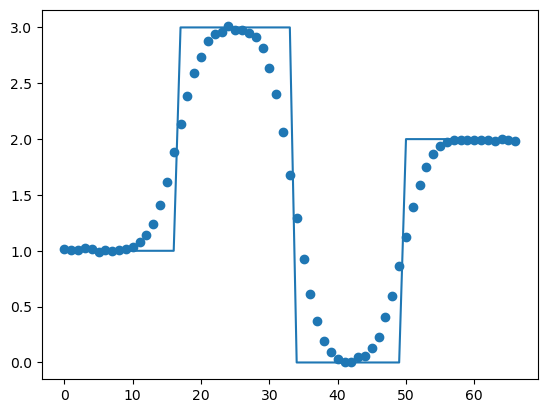

In [15]:
plt.plot(grid, ground_truth)
plt.scatter(grid, b)
plt.show()

In [16]:
data = dp_cubic(A, L, b, noise_stdev**2, eta=1.01, maxiter=35, beta0=None, rtol=1e-3, early_stopping=True)

5.1868551624459705e-06
67
66
67

1.5012117619269602e-05
67
66
67

3.79806976343843e-05
67
66
67

0.00010602791998119659
67
66
67

0.0003910761424223411
67
66
67

0.0011765683555564849
67
66
67

0.002751997368022301
67
66
67

0.005332435331979097
67
66
67

0.008026709855392396
67
66
67

0.008817675719395733
67
66
67

0.00882857917561361
67
66
67

0.008828579203578123
67
66
67



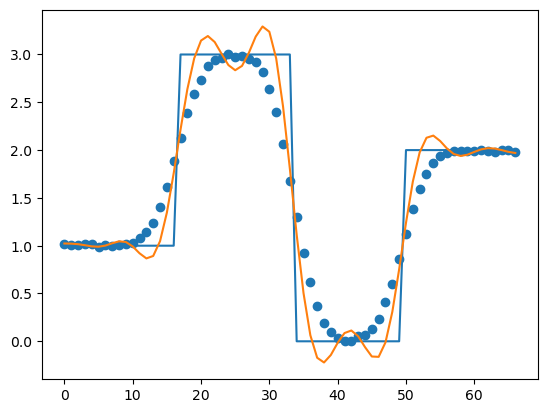

In [19]:
plt.plot(grid, ground_truth)
plt.scatter(grid, b)
plt.plot(data["xbeta"])
plt.show()

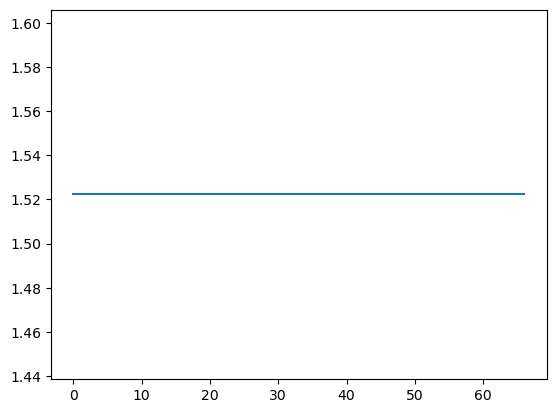

In [18]:
plt.plot(xker)
plt.show()

In [21]:
data = dp_val(A @ Lopinv, np.eye(L.shape[0]), b - A @ xker, noise_stdev**2, eta=1.01, maxiter=35, beta0=None, rtol=1e-3, early_stopping=True)
#data = dp_cubic(A @ Lopinv, np.eye(L.shape[0]), b - A @ xker, noise_stdev**2, eta=1.01, maxiter=35, beta0=None, rtol=1e-3, early_stopping=True)

1.01


In [22]:
x2 = (Lopinv @ data["xbeta"]) + xker

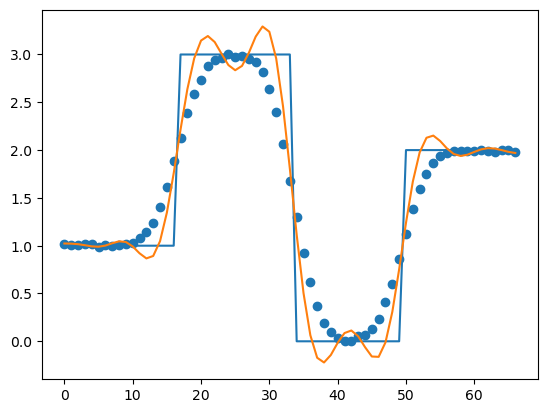

In [23]:
plt.plot(grid, ground_truth)
plt.scatter(grid, b)
plt.plot(x2)
plt.show()